# LAB 2
## Anomaly Detection and Cluster Analysis using Country Schools Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("Country Schools.csv")

In [3]:
df.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


# df.head() 
## The first five records of the Country Schools dataset were displayed successfully.

In [5]:
df.shape

(50, 8)

## This output shows the number of rows and columns in the dataset.
COMMAND USED IS:  df.shape

In [7]:
df.columns

Index(['SNO', 'TOTALSCHOOLS', 'TotalSchoolsInstalled', 'SchoolsPending',
       'PercentageInstalled', 'InstalledLDDs', 'InstalledTDDs', 'FID'],
      dtype='object')

## above data dispalying column names
command used: df.columns

In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     object 
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     object 
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 3.3+ KB


## The output shows each column and its data type.
command: df.info()

In [11]:
df.isnull().sum()

SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

## Above informations shows how many data missing in each column
command: df.isnull().sum()

In [13]:
df.dropna()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5
5,TAITA TAVETA,194.0,172.0,22.0,88.66%,6412.0,344.0,6
6,UASIN GISHU,456.0,353.0,103.0,77.41%,16024.0,706.0,7
7,MIGORI,601.0,413.0,188.0,68.72%,24453.0,826.0,8
8,VIHIGA,378.0,307.0,71.0,81.22%,18559.0,614.0,9
9,NYAMIRA,406.0,351.0,55.0,86.45%,14974.0,702.0,10


## that was cleaning the missing values
command: df.dropna()

In [14]:
df.isnull().sum()

SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

## above output is for checking if the na (not available) is removed
formular used:df.isnull.sum()

# Let Make convesion of Numbers and word
becouse machinelearning does not make calculation and other operation with text instead of numbers

In [15]:
df["PercentageInstalled"]=df["PercentageInstalled"].str.replace("%","")
df["PercentageInstalled"]=df["PercentageInstalled"].astype(float)

# Convert County Names to Numbers
County names were converted into numeric values for machine learning analysis.

In [18]:
le = LabelEncoder()
df["SNO"] = le.fit_transform(df["SNO"])

# Again checking datatypes
Most attributes are now numerical and ready for analysis.

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    50 non-null     int64  
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     float64
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(6), int64(2)
memory usage: 3.3 KB


# ANOMALY DETECTION
Lets create anomaly detection model

In [21]:
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

#  Let find if there is an anomaly to be detected
command to use:  df["anomaly"]=model.fit_predict(df)

In [22]:
df["anomaly"]=model.fit_predict(df)

## Lets see theresult about an anomalies
Lets view result

In [23]:
df["anomaly"].value_counts()

anomaly
 1    47
-1     3
Name: count, dtype: int64

# Let check those anomalies counted
They showed that anomaloes detected are 3

In [25]:
df[df["anomaly"] == -1]

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID,anomaly
0,43,358.0,37.0,321.0,10.34,3744.0,74.0,1,-1
3,17,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4,-1
47,41,21729.0,14629.0,7100.0,67.32,723618.0,29258.0,48,-1


# Draw Anomaly Graph
These grath shows well the anomaly

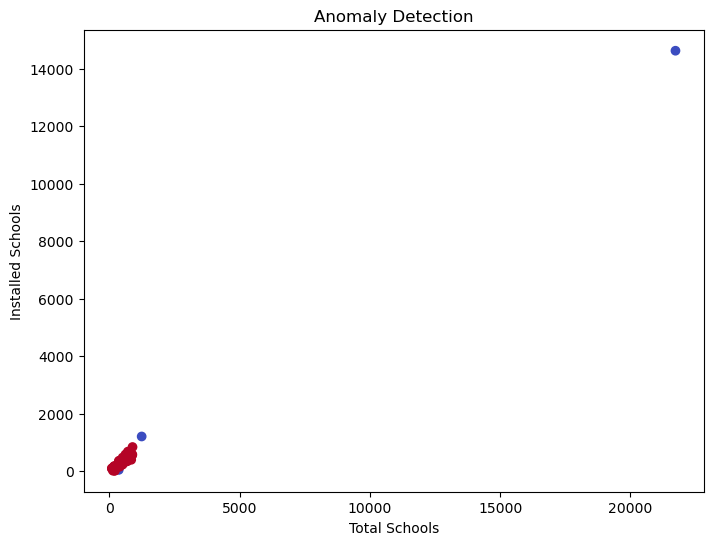

In [29]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df["TOTALSCHOOLS"],
    df["TotalSchoolsInstalled"],
    c=df["anomaly"], 
    cmap="coolwarm"  
)
plt.xlabel("Total Schools")
plt.ylabel("Installed Schools")
plt.title("Anomaly Detection")
plt.show()

# Lets work with CLUSTER ANALYSIS
This is making standardilised data
Also is making Grop of data the one which is similar

In [31]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    df.drop("anomaly", axis=1)
)

# Lets create Groups
groups created by using Kmeans

In [32]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

# Lets save the Group created
Running the Model and Saving Results (

In [41]:
# 1. Drop any rows that contain missing values (NaNs)
df_clean = df.dropna().copy()

# 2. Prepare your features from the clean dataset (excluding non-numeric or label columns like 'Anomaly')
features = df_clean.drop(columns=["anomaly", "SNO"], errors="ignore")

# 3. Scale the clean features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)

# 4. Run K-Means and save the clusters back to df_clean
kmeans = KMeans(n_clusters=3, random_state=42)
df_clean["Cluster"] = kmeans.fit_predict(scaled_data)

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


# Viewing Cluster Counts
The dataset was grouped into three clusters of similar counties.

In [45]:
df_clean["Cluster"].value_counts()

Cluster
2    26
0    21
1     1
Name: count, dtype: int64

# Analyzing Clusters
The table shows the average characteristics of each cluster(each group).

In [47]:
df_clean.groupby("Cluster").mean()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID,anomaly
Cluster,,,,,,,,,
0,23.000000,385.380952,183.571429,201.809524,43.064286,7409.238095,367.142857,35.523810,0.904762
1,41.000000,21729.000000,14629.000000,7100.000000,67.320000,723618.000000,29258.000000,48.000000,-1.000000
2,23.230769,524.461538,414.384615,110.076923,80.763462,21847.076923,828.769231,14.692308,0.923077


# Visualize Clusters
Different colors represent different groups of counties with similar characteristics.

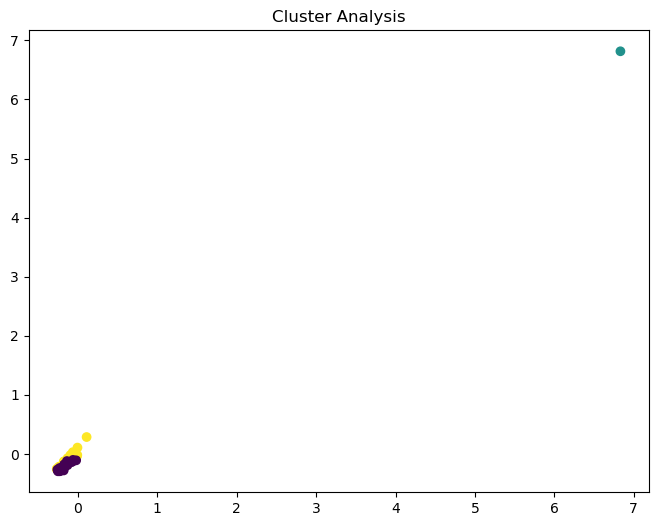

In [49]:
plt.figure(figsize=(8,6))

plt.scatter(
    scaled_data[:,0],
    scaled_data[:,1],
    c=df_clean["Cluster"]
)

plt.title("Cluster Analysis")

plt.show()

# Conclusion
The Country Schools dataset was cleaned and prepared for analysis. Missing values were removed, and percentage values were changed into numbers. Anomaly detection helped identify counties that were different from most other counties. Cluster analysis grouped counties with similar characteristics together. These techniques help us identify similarities, differences, and unusual counties in the dataset. This makes the data easier to understand and analyze.